# Risk Modelling Case Study: Predicting Loan Defaulters

**Goal:** build a model that flags customers likely to default on a loan, evaluate it the way a credit-risk team would (precision, recall, F1 — not just accuracy), and explain *why* the model flags each customer using SHAP.

**Contents**
1. Business problem & data
2. Exploratory data analysis
3. Feature engineering & preprocessing
4. Modeling: Logistic Regression baseline vs. XGBoost
5. Evaluation: precision, recall, F1, confusion matrix, PR/ROC curves
6. Decision-threshold tuning
7. Explainability with SHAP
8. Business takeaways

> **Note on data:** this notebook uses a *synthetic* loan portfolio (15,000 records) generated in `src/generate_data.py`. It's built to mimic real consumer-lending bureau/application data (credit score, DTI, utilization, delinquencies, etc.) with a simulated, noisy default outcome — so the workflow and pitfalls (class imbalance, precision/recall tradeoffs, feature drivers) are realistic even though no real customer data is involved.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
plt.rcParams['figure.dpi'] = 100
sns.set_style('whitegrid')


## 1. Load the data

In [2]:
df = pd.read_csv('../data/loan_data.csv')
print(df.shape)
df.head()


(15000, 17)


,customer_id,age,annual_income,employment_length_years,home_ownership,credit_score,credit_utilization,delinquencies_2yrs,months_since_last_delinquency,open_credit_lines,existing_loans_count,loan_purpose,loan_amount,loan_term_months,interest_rate,debt_to_income_ratio,default
0,CUST100000,43,20001.0,10.4,MORTGAGE,591,0.476,1,41,13,0,business,10295.0,60,22.07,0.750,1
1,CUST100001,29,50520.0,5.0,RENT,646,0.433,0,999,6,0,debt_consolidation,4206.0,60,15.44,0.308,0
2,CUST100002,48,30862.0,13.8,MORTGAGE,598,0.217,0,999,10,0,credit_card,6124.0,36,16.98,0.363,1
3,CUST100003,50,68374.0,0.2,OWN,653,0.434,2,16,4,1,auto,9790.0,36,15.76,0.327,0
4,CUST100004,20,62989.0,1.7,RENT,835,0.232,1,7,4,1,home_improvement,14568.0,60,11.10,0.396,0


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 17 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   customer_id                    15000 non-null  str    
 1   age                            15000 non-null  int64  
 2   annual_income                  15000 non-null  float64
 3   employment_length_years        15000 non-null  float64
 4   home_ownership                 15000 non-null  str    
 5   credit_score                   15000 non-null  int64  
 6   credit_utilization             15000 non-null  float64
 7   delinquencies_2yrs             15000 non-null  int64  
 8   months_since_last_delinquency  15000 non-null  int64  
 9   open_credit_lines              15000 non-null  int64  
 10  existing_loans_count           15000 non-null  int64  
 11  loan_purpose                   15000 non-null  str    
 12  loan_amount                    15000 non-null  float64
 1

In [4]:
default_rate = df['default'].mean()
print(f"Overall default rate: {default_rate:.2%}")
df['default'].value_counts(normalize=True).rename({0: 'Non-default', 1: 'Default'})


Overall default rate: 23.75%


default
Non-default    0.762467
Default        0.237533
Name: proportion, dtype: float64

### Class imbalance

Roughly 1 in 4 loans defaults in this dataset. This is realistic for a *higher-risk* consumer lending book (subprime / near-prime); for prime mortgage or auto books the true rate is usually much lower (2-8%). The imbalance matters a lot for how we choose and evaluate a model — **accuracy is a misleading metric here**: a model that predicts "no default" for everyone would already be ~76% accurate while catching zero risk.

## 2. Exploratory data analysis

/tmp/ipykernel_6542/3390824545.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1,0].set_xticklabels(['Non-default', 'Default'])


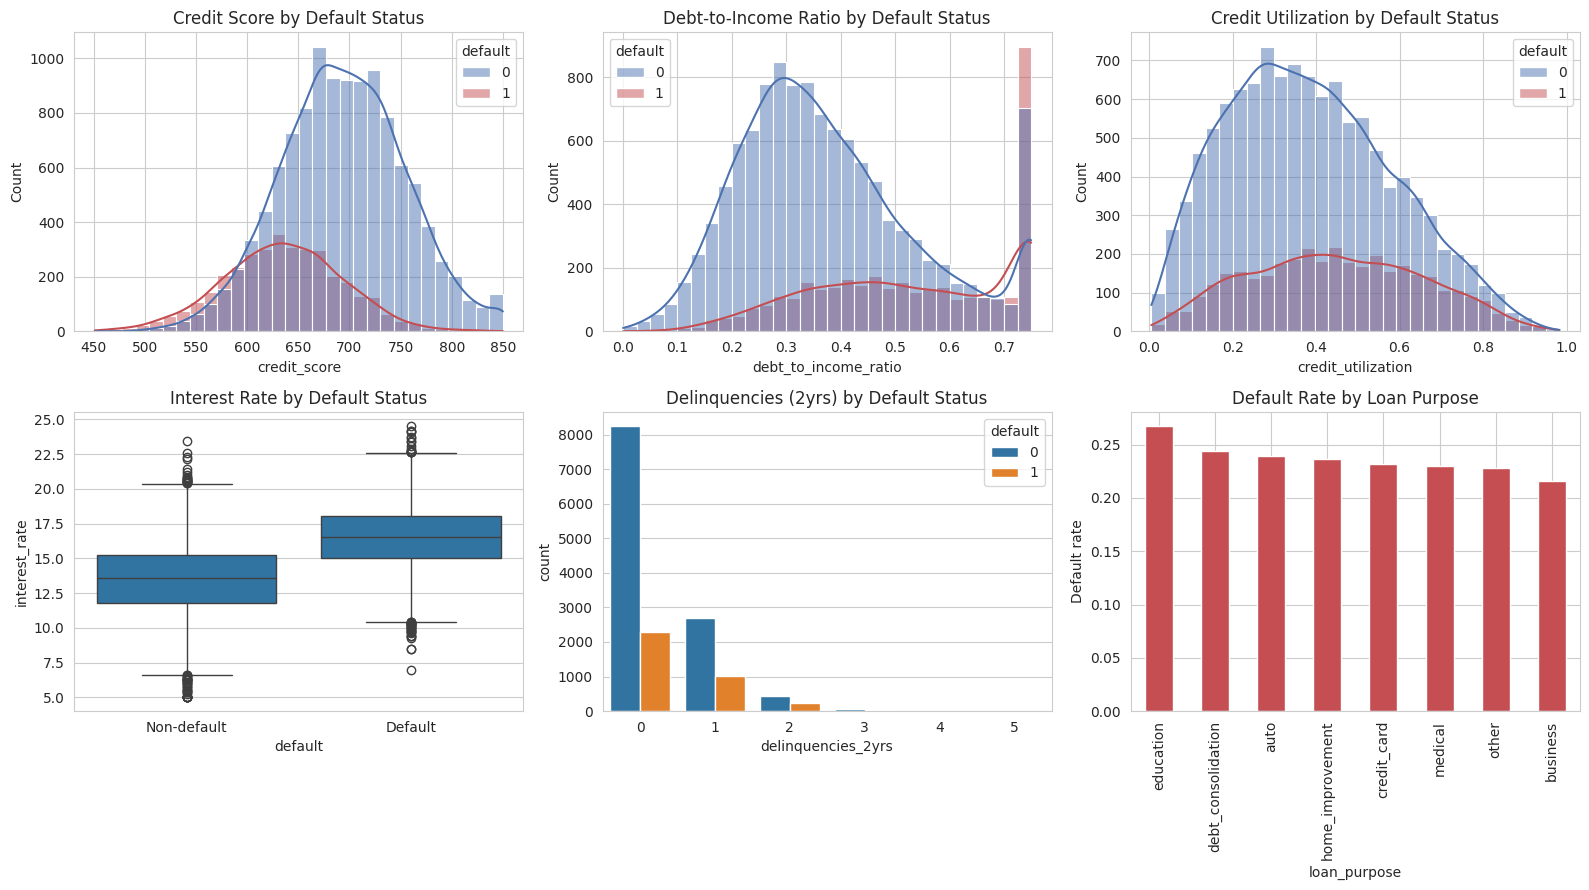

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

sns.histplot(data=df, x='credit_score', hue='default', bins=30, kde=True, ax=axes[0,0], palette=['#4C72B0', '#C44E52'])
axes[0,0].set_title('Credit Score by Default Status')

sns.histplot(data=df, x='debt_to_income_ratio', hue='default', bins=30, kde=True, ax=axes[0,1], palette=['#4C72B0', '#C44E52'])
axes[0,1].set_title('Debt-to-Income Ratio by Default Status')

sns.histplot(data=df, x='credit_utilization', hue='default', bins=30, kde=True, ax=axes[0,2], palette=['#4C72B0', '#C44E52'])
axes[0,2].set_title('Credit Utilization by Default Status')

sns.boxplot(data=df, x='default', y='interest_rate', ax=axes[1,0])
axes[1,0].set_title('Interest Rate by Default Status')
axes[1,0].set_xticklabels(['Non-default', 'Default'])

sns.countplot(data=df, x='delinquencies_2yrs', hue='default', ax=axes[1,1])
axes[1,1].set_title('Delinquencies (2yrs) by Default Status')

default_by_purpose = df.groupby('loan_purpose')['default'].mean().sort_values(ascending=False)
default_by_purpose.plot(kind='bar', ax=axes[1,2], color='#C44E52')
axes[1,2].set_title('Default Rate by Loan Purpose')
axes[1,2].set_ylabel('Default rate')

plt.tight_layout()
plt.show()


**Observations:** defaulters skew toward lower credit scores, higher debt-to-income ratios, higher credit utilization, higher interest rates (which are themselves priced off risk) and more prior delinquencies — all consistent with how real credit risk models behave. This gives us confidence the synthetic data has learnable, realistic structure rather than being pure noise.

## 3. Feature engineering & preprocessing

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

NUMERIC_FEATURES = [
    'age', 'annual_income', 'employment_length_years', 'credit_score',
    'credit_utilization', 'delinquencies_2yrs', 'months_since_last_delinquency',
    'open_credit_lines', 'existing_loans_count', 'loan_amount',
    'loan_term_months', 'interest_rate', 'debt_to_income_ratio',
]
CATEGORICAL_FEATURES = ['home_ownership', 'loan_purpose']
TARGET = 'default'

X = df[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), NUMERIC_FEATURES),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), CATEGORICAL_FEATURES),
])

print(f"Train: {X_train.shape}, Test: {X_test.shape}")


Train: (11250, 15), Test: (3750, 15)


We stratify the train/test split on the target so both sets preserve the ~24% default rate. Numeric features are standardized (important for the Logistic Regression baseline); categoricals are one-hot encoded.

## 4. Modeling: Logistic Regression baseline vs. XGBoost

We deliberately train **two models**:
- **Logistic Regression** — an interpretable, fast baseline that risk teams often keep in production for governance/regulatory reasons.
- **XGBoost** — a gradient-boosted tree model that usually captures non-linearities and interactions better.

Both use class-balancing (`class_weight='balanced'` / `scale_pos_weight`) since defaults are the minority class we actually care about.

In [7]:
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

logreg = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)),
])
logreg.fit(X_train, y_train)
logreg_proba = logreg.predict_proba(X_test)[:, 1]

n_pos, n_neg = (y_train == 1).sum(), (y_train == 0).sum()
xgb_clf = XGBClassifier(
    n_estimators=400, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
    scale_pos_weight=n_neg / n_pos, eval_metric='logloss', random_state=42,
)
xgb_model = Pipeline([('prep', preprocessor), ('clf', xgb_clf)])
xgb_model.fit(X_train, y_train)
xgb_proba = xgb_model.predict_proba(X_test)[:, 1]

print("Models trained.")


Models trained.


## 5. Evaluation: precision, recall, F1 (the metrics that matter for defaulters)

**Why not accuracy?** With ~76% of loans non-defaulting, a trivial "always predict no default" model scores 76% accuracy while catching zero risk. For a defaulter-detection model we care about:

- **Precision (default class):** of the customers we flag as high-risk, how many actually default? Low precision → we waste collections/underwriting effort chasing false alarms.
- **Recall (default class):** of the customers who actually default, how many did we catch? Low recall → real risk slips through unflagged, costing the bank in write-offs.
- **F1:** harmonic mean of the two — a single number for the precision/recall tradeoff.

There is no free lunch: tightening the decision threshold to catch more defaulters (higher recall) means flagging more good customers too (lower precision), and vice versa. Where you sit on that curve is a **business decision**, not a modeling one.

In [8]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, average_precision_score

for name, proba in [('Logistic Regression', logreg_proba), ('XGBoost', xgb_proba)]:
    pred = (proba >= 0.5).astype(int)
    print(f"\n===== {name} (threshold=0.50) =====")
    print(classification_report(y_test, pred, target_names=['Non-default', 'Default']))
    print(f"ROC-AUC: {roc_auc_score(y_test, proba):.4f}  |  PR-AUC: {average_precision_score(y_test, proba):.4f}")



===== Logistic Regression (threshold=0.50) =====
              precision    recall  f1-score   support

 Non-default       0.93      0.80      0.86      2859
     Default       0.55      0.80      0.65       891

    accuracy                           0.80      3750
   macro avg       0.74      0.80      0.75      3750
weighted avg       0.84      0.80      0.81      3750

ROC-AUC: 0.8794  |  PR-AUC: 0.7188

===== XGBoost (threshold=0.50) =====
              precision    recall  f1-score   support

 Non-default       0.92      0.81      0.86      2859
     Default       0.56      0.77      0.64       891

    accuracy                           0.80      3750
   macro avg       0.74      0.79      0.75      3750
weighted avg       0.83      0.80      0.81      3750

ROC-AUC: 0.8728  |  PR-AUC: 0.6992


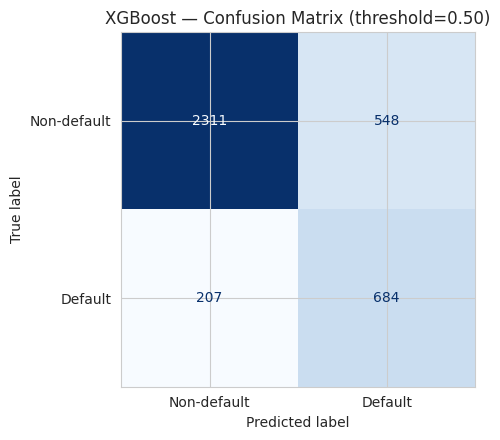

In [9]:
fig, ax = plt.subplots(figsize=(5, 4.5))
cm = confusion_matrix(y_test, (xgb_proba >= 0.5).astype(int))
ConfusionMatrixDisplay(cm, display_labels=['Non-default', 'Default']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('XGBoost — Confusion Matrix (threshold=0.50)')
plt.tight_layout()
plt.show()


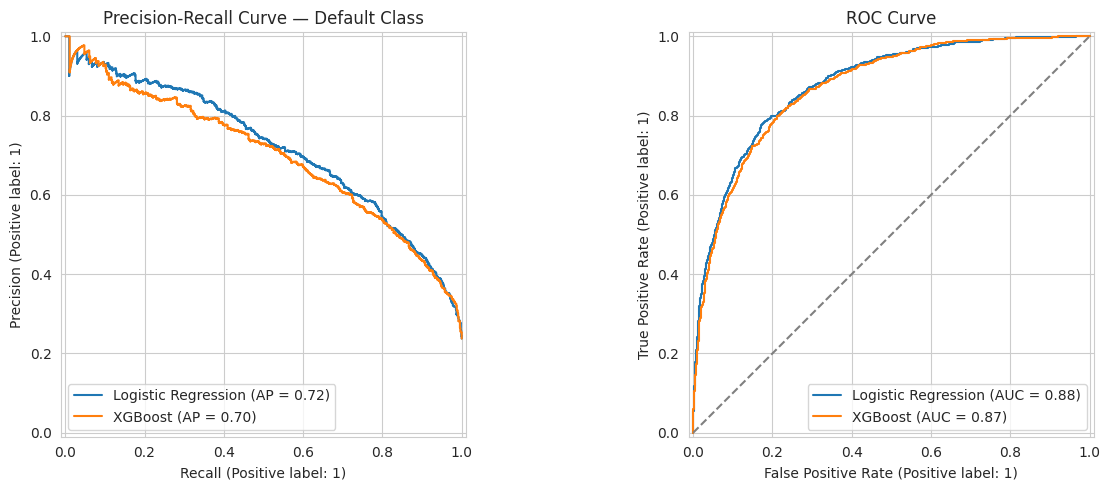

In [10]:
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
PrecisionRecallDisplay.from_predictions(y_test, logreg_proba, name='Logistic Regression', ax=axes[0])
PrecisionRecallDisplay.from_predictions(y_test, xgb_proba, name='XGBoost', ax=axes[0])
axes[0].set_title('Precision-Recall Curve — Default Class')

RocCurveDisplay.from_predictions(y_test, logreg_proba, name='Logistic Regression', ax=axes[1])
RocCurveDisplay.from_predictions(y_test, xgb_proba, name='XGBoost', ax=axes[1])
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[1].set_title('ROC Curve')

plt.tight_layout()
plt.show()


## 6. Decision-threshold tuning

The default 0.5 cutoff is arbitrary. We scan thresholds and pick the one that maximizes F1 on the default class — a reasonable starting point before a real risk team overlays cost-of-default vs. cost-of-false-positive economics.

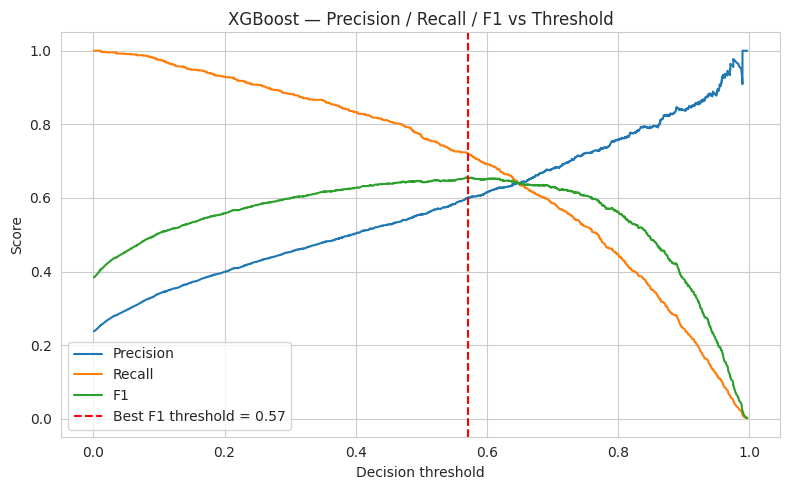

Tuned threshold: 0.570
Precision (default): 0.601
Recall (default):    0.723
F1 (default):         0.656


In [11]:
from sklearn.metrics import precision_recall_curve, f1_score, precision_score, recall_score

precisions, recalls, thresholds = precision_recall_curve(y_test, xgb_proba)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-12)
best_idx = np.argmax(f1_scores[:-1])
best_threshold = thresholds[best_idx]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(thresholds, precisions[:-1], label='Precision')
ax.plot(thresholds, recalls[:-1], label='Recall')
ax.plot(thresholds, f1_scores[:-1], label='F1')
ax.axvline(best_threshold, color='red', linestyle='--', label=f'Best F1 threshold = {best_threshold:.2f}')
ax.set_xlabel('Decision threshold')
ax.set_ylabel('Score')
ax.set_title('XGBoost — Precision / Recall / F1 vs Threshold')
ax.legend()
plt.tight_layout()
plt.show()

xgb_pred_tuned = (xgb_proba >= best_threshold).astype(int)
print(f"Tuned threshold: {best_threshold:.3f}")
print(f"Precision (default): {precision_score(y_test, xgb_pred_tuned):.3f}")
print(f"Recall (default):    {recall_score(y_test, xgb_pred_tuned):.3f}")
print(f"F1 (default):         {f1_score(y_test, xgb_pred_tuned):.3f}")


## 7. Explainability with SHAP

A precision/recall number tells us *how well* the model separates defaulters from non-defaulters. It doesn't tell us *why* a given customer was flagged — and in consumer lending, "why" matters for adverse-action notices, fair-lending compliance, and for underwriters who need to trust and act on the score. We use **SHAP (SHapley Additive exPlanations)** to attribute each prediction to its input features.

In [12]:
import shap

preprocessor_fitted = xgb_model.named_steps['prep']
clf_fitted = xgb_model.named_steps['clf']

sample = X_test.sample(n=1500, random_state=42)
X_sample_transformed = preprocessor_fitted.transform(sample)
if hasattr(X_sample_transformed, 'toarray'):
    X_sample_transformed = X_sample_transformed.toarray()

feature_names = NUMERIC_FEATURES + list(
    preprocessor_fitted.named_transformers_['cat'].get_feature_names_out(CATEGORICAL_FEATURES)
)
X_sample_df = pd.DataFrame(X_sample_transformed, columns=feature_names, index=sample.index)

explainer = shap.TreeExplainer(clf_fitted)
shap_values = explainer.shap_values(X_sample_df)
shap_values_default = shap_values[1] if isinstance(shap_values, list) else shap_values

print("SHAP values computed for", X_sample_df.shape[0], "customers")


SHAP values computed for 1500 customers


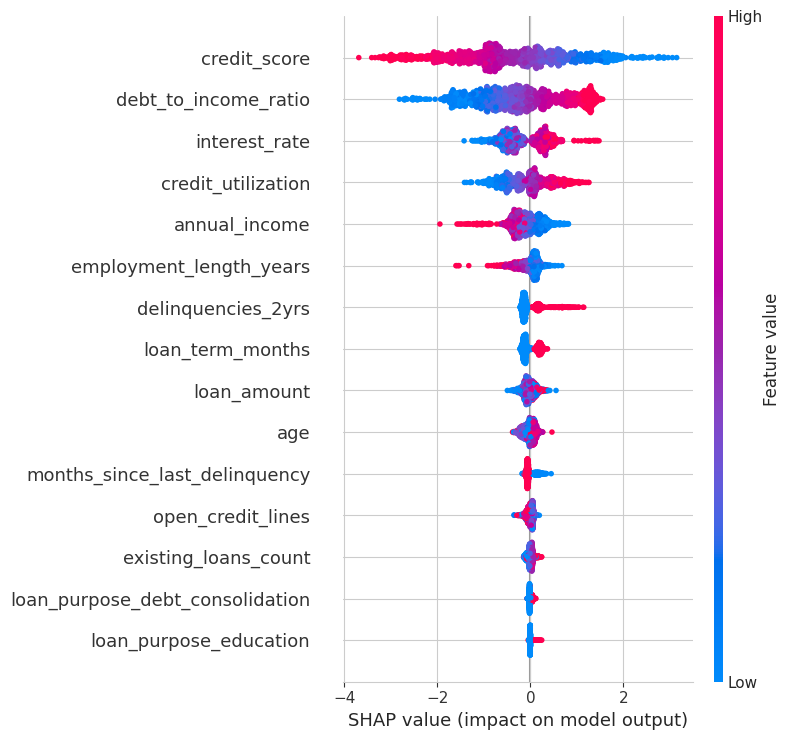

In [13]:
shap.summary_plot(shap_values_default, X_sample_df, max_display=15)


**Reading the beeswarm plot:** each dot is one customer. Position on the x-axis is that feature's SHAP value (how much it pushed the prediction toward "default" (+) or "non-default" (-) for that customer); color is the feature's actual value (red = high, blue = low).

**Takeaway:** low credit scores (blue dots pushed to the right on the `credit_score` row), along with high debt-to-income ratio, high interest rate and high credit utilization (red dots pushed to the right on those rows), are consistently the strongest and most intuitive drivers of predicted default risk — exactly what a credit officer would expect, which is a good sanity check on the model.

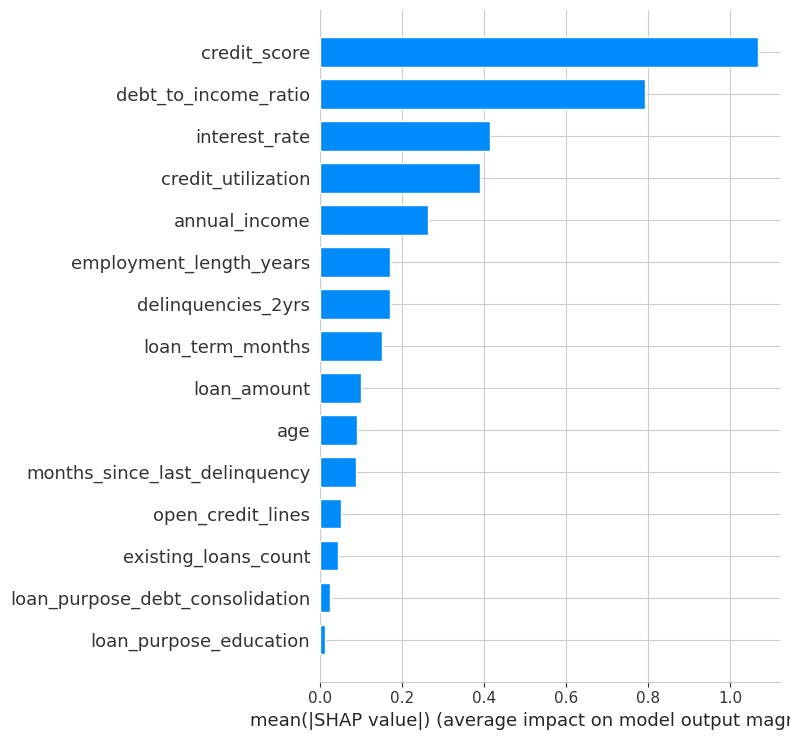

In [14]:
shap.summary_plot(shap_values_default, X_sample_df, plot_type='bar', max_display=15)


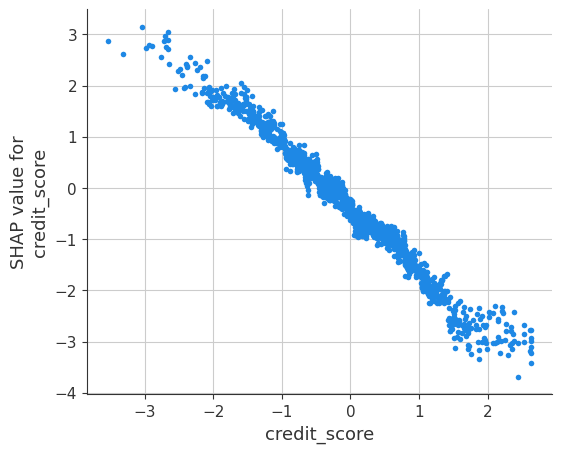

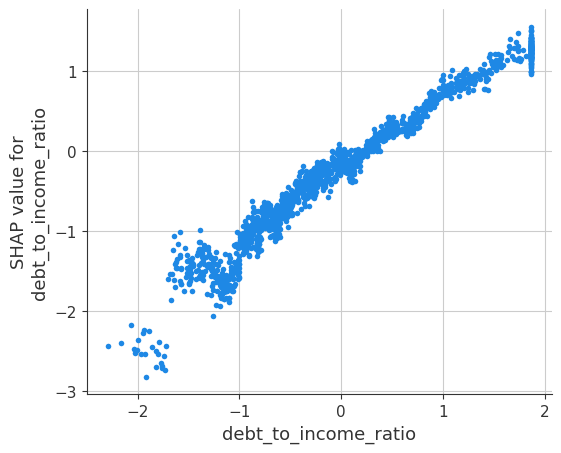

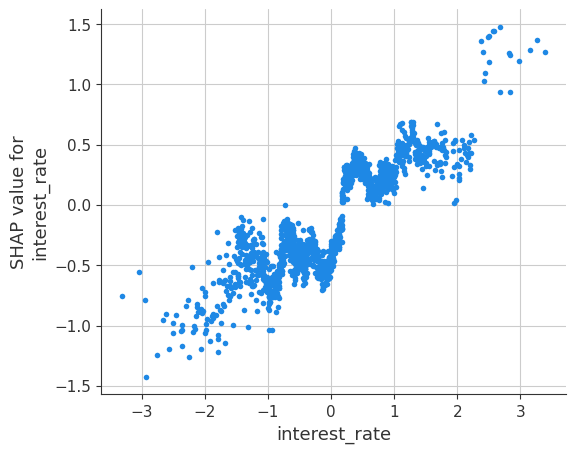

In [15]:
top_features = pd.Series(np.abs(shap_values_default).mean(axis=0), index=feature_names).sort_values(ascending=False).head(3)
for feat in top_features.index:
    shap.dependence_plot(feat, shap_values_default, X_sample_df, interaction_index=None)


### Local explanation for a single flagged customer

Global summary plots explain the model on average. In production, an underwriter needs a **per-customer** explanation — this is what would go into an internal risk memo or (in principle, with the right governance) an adverse-action notice.

In [16]:
proba_sample = xgb_model.predict_proba(sample)[:, 1]
sample_info = sample.copy()
sample_info['predicted_risk'] = proba_sample
sample_info['actual_default'] = df.loc[sample.index, 'default']

flagged_defaulter = sample_info[(sample_info['actual_default'] == 1) & (sample_info['predicted_risk'] > 0.7)]
example_idx = flagged_defaulter.index[0] if len(flagged_defaulter) else sample_info.sort_values('predicted_risk', ascending=False).index[0]
example_pos = sample.index.get_loc(example_idx)

print(df.loc[example_idx])
print(f"\nPredicted default risk: {proba_sample[example_pos]:.1%}")


customer_id                      CUST102696
age                                      45
annual_income                       71427.0
employment_length_years                 3.7
home_ownership                         RENT
credit_score                            584
credit_utilization                    0.386
delinquencies_2yrs                        0
months_since_last_delinquency           999
open_credit_lines                         6
existing_loans_count                      2
loan_purpose                       business
loan_amount                         38231.0
loan_term_months                         60
interest_rate                          18.6
debt_to_income_ratio                   0.75
default                                   1
Name: 2696, dtype: object

Predicted default risk: 96.0%


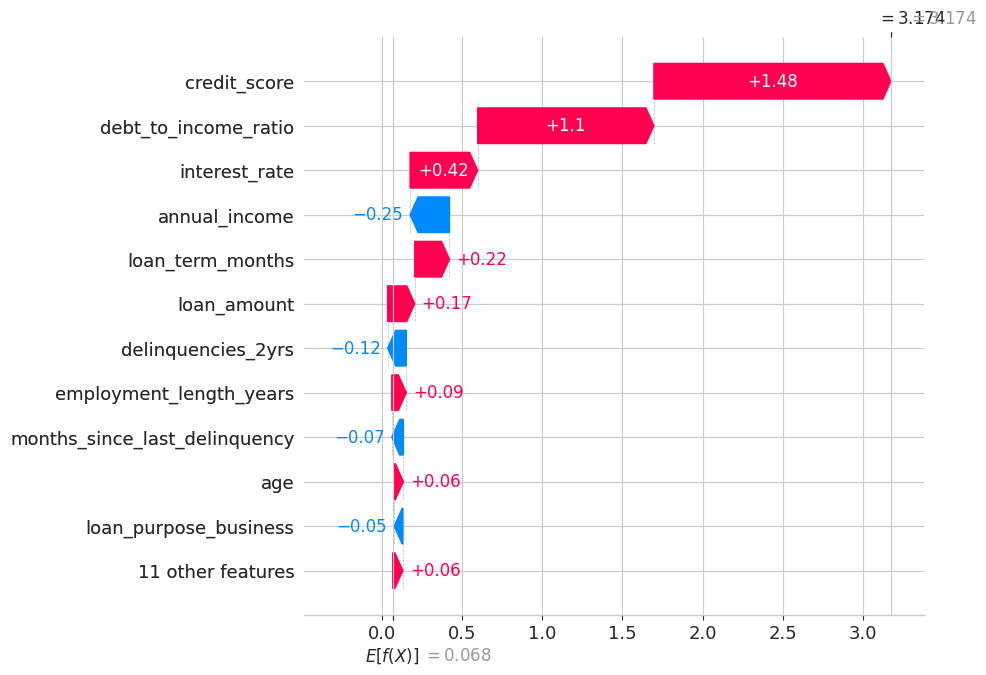

In [17]:
expected_value = explainer.expected_value
if isinstance(expected_value, (list, np.ndarray)):
    expected_value = expected_value[1] if len(np.shape(expected_value)) else expected_value

shap.plots._waterfall.waterfall_legacy(
    expected_value,
    shap_values_default[example_pos],
    feature_names=feature_names,
    max_display=12,
)


This customer was flagged mainly because of a low credit score, high debt-to-income ratio and elevated credit utilization — each visibly pushing the predicted risk above the base rate. This is the kind of explanation a collections or underwriting team can act on directly (e.g. "offer a lower loan amount / require a co-signer / decline" with a documented reason).

## 8. Business takeaways

- **Model choice:** XGBoost and Logistic Regression perform similarly on ROC-AUC (~0.87–0.88) here — the relationships in this data are fairly linear/monotonic (as engineered). In practice, XGBoost usually pulls further ahead when there are real feature interactions and non-linearities; keeping the interpretable Logistic Regression as a benchmark/challenger model is good governance practice for regulated credit decisions.
- **Precision/recall tradeoff is a business decision, not a modeling one.** At the default 0.5 threshold the model catches ~77% of defaulters but only about 1 in 2 flagged customers actually defaults. Raising the threshold (tuned to ~0.57) trades some recall for meaningfully better precision — fewer false alarms per true catch. The right operating point depends on the relative cost of a missed default vs. the cost of unnecessarily declining/escalating a good customer.
- **SHAP confirms the model is learning sensible, explainable risk signal** — credit score, DTI, utilization, and pricing (interest rate) dominate, matching domain intuition. This matters both for trust/adoption by underwriting teams and for fair-lending explainability requirements.
- **Next steps for a production version:** calibrate probabilities (e.g. Platt scaling) if scores feed into a pricing/decision engine that assumes calibrated probabilities; run fairness/disparate-impact checks across protected classes; add temporal validation (train on older vintages, test on newer ones) instead of a random split, since credit risk models drift with macro conditions; and monitor for population/feature drift over time.
